# Interpreting a CatBoost ranker

For each WANDS search query, rank candidate products by relevance
(`Exact = 2`, `Partial = 1`, `Irrelevant = 0`). Train a CatBoost ranker,
explain why it puts one product above another, and test whether fewer features
preserve top-five ranking quality on unseen queries. `random_noise` is a control feature.

Install the dependencies with `pip install -r requirements-seminar.txt`.
Keep the notebook next to `seminar_utils.py`.

In [1]:
import os

for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[name] = "4"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from seminar_utils import (
    FEATURES,
    NAMES,
    SEED,
    THREADS,
    cards,
    fit_ranker,
    lime_coordinates,
    lime_prediction,
    load_wands,
    make_pool,
    ndcg,
    predict,
    sample_queries,
)

pd.set_option("display.max_colwidth", 80)

In [2]:
table, manifest = load_wands()
train = table[table.split.eq("train")].reset_index(drop=True)
valid = table[table.split.eq("validation")].reset_index(drop=True)
test = table[table.split.eq("test")].reset_index(drop=True)
demo = valid[valid.query_id.eq(manifest["demo_query_id"])].reset_index(drop=True)

assert set(train.query_id).isdisjoint(set(valid.query_id) | set(test.query_id))
assert set(valid.query_id).isdisjoint(test.query_id)

print("Query:", demo["query"].iloc[0])
display(cards(demo.groupby("label", sort=False).head(2)))
display(pd.Series(NAMES, name="Feature description"))

Query: turquoise pillows


,product_id,Product,Relevance,Query-term coverage,Title similarity,Rating
0,22,miles body pillow case,Partial,0.0,0.0,0.0
1,23,vienna body pillow case,Partial,0.0,0.0,0.0
3,60,wimberley 56 '' pillow top arm reclining loveseat,Irrelevant,0.0,0.0,5.0
4,61,wimberley 76 '' pillow top arm reclining sofa,Irrelevant,0.0,0.0,4.5
28,881,telford beaded dragonfly square pillow cover & insert,Exact,0.0,0.0,5.0
42,1851,newsome linen throw pillow,Exact,0.0,0.0,4.5


title_coverage                Query-term coverage in title
description_coverage    Query-term coverage in description
attributes_coverage      Query-term coverage in attributes
title_tfidf                Query-title similarity (TF-IDF)
exact_phrase                   Exact query phrase in title
title_length                          Title length (words)
average_rating                Average rating (0 = missing)
has_rating                                Rating available
log_rating_count                     log(1 + rating count)
log_review_count                     log(1 + review count)
query_length                          Query length (words)
random_noise                        Random control feature
Name: Feature description, dtype: object

## Model and metric

$$\mathrm{DCG@}k=\sum_{i=1}^{\min(k,n_q)}\frac{2^{r_{\pi_i}}-1}{\log_2(i+1)},
\qquad \mathrm{NDCG@}k=\frac{\mathrm{DCG@}k}{\mathrm{IDCG@}k}.$$

- For query $q$ with $n_q$ candidates, sum over positions $i$ from 1 to $\min(k,n_q)$. The cutoff here is $k=5$.
- $\pi_i$ is the product at position $i$ in descending order of raw model score. Its true relevance $r_{\pi_i}$ determines its gain $2^{r_{\pi_i}}-1$ (3 for an exact match, 1 for partial, 0 for irrelevant).
- Discounted cumulative gain (DCG) sums these gains, dividing each by $\log_2(i+1)$ so earlier matches count more. IDCG is the DCG for the same products sorted by decreasing true relevance. Normalized DCG is the fraction of this ideal gain, with 1 for an ideal top $k$.

[CatBoost's NDCG formula](https://catboost.ai/docs/en/references/ndcg) · [Järvelin and Kekäläinen (2002)](https://doi.org/10.1145/582415.582418)

Compare CatBoost with sorting by `title_tfidf`, averaging NDCG@5 equally across validation queries.
Split by query. Use validation for early stopping and feature selection, and test for the final comparison.

In [3]:
full_model = fit_ranker(train, valid)
valid_scores = predict(full_model, valid)
full_valid_score = ndcg(valid, valid_scores)
demo_scores = predict(full_model, demo)

baseline_scores = pd.Series(
    {
        "TF-IDF": ndcg(valid, valid.title_tfidf.to_numpy()),
        "CatBoost": full_valid_score,
    },
    name="Validation NDCG@5",
)

display(baseline_scores)
display(cards(demo, demo_scores))

TF-IDF      0.602801
CatBoost    0.769710
Name: Validation NDCG@5, dtype: float64

,product_id,Product,Relevance,Query-term coverage,Title similarity,Rating,Score
194,7965,"gosnell 2-piece outdoor patio furniture taupe , open-weave wicker love seat ...",Exact,1.0,0.329,4.5,1.400
497,18292,bunton indoor/outdoor throw pilow,Exact,0.0,0.000,4.5,1.030
951,40484,broughton very soft and comfy plush faux throw pillow,Exact,0.0,0.000,4.5,1.014
853,34759,tommy bahama coral bay rectangular pillow cover & insert,Partial,0.0,0.000,5.0,0.966
498,18293,brocklesby outdoor square pillow cover and insert,Exact,0.0,0.000,5.0,0.958
852,34758,tommy bahama starfish geo square pillow cover & insert,Partial,0.0,0.000,0.0,0.957


### Built-in feature importance

For ranking, CatBoost's default feature importance is `LossFunctionChange`.
It estimates how removing a feature affects the loss without retraining the model.
Our training loss is PairLogit; this importance is not a change in NDCG.

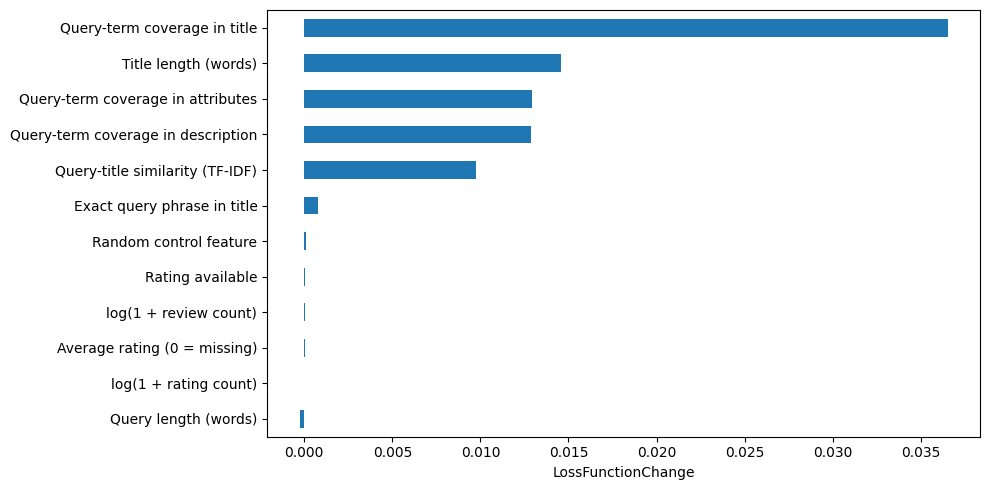

In [4]:
native_values = full_model.get_feature_importance(
    make_pool(valid),
    type="LossFunctionChange",
    thread_count=THREADS,
)
native_importance = pd.Series(native_values, index=FEATURES)

native_importance.sort_values().rename(index=NAMES).plot.barh(figsize=(10, 5))
plt.xlabel("LossFunctionChange")
plt.tight_layout()
plt.show()

## Exercise 1. ICE and PDP

$$C_{rk}=f(t_k,x^{(r)}_{-j}),\quad
\mathrm{cICE}_{rk}=C_{rk}-C_{r0},\quad
\mathrm{PDP}(t_k)=\frac1n\sum_r C_{rk}.$$

Row $r$ is one of $n$ sampled query–product pairs. Set feature $j$ (`title_tfidf`)
to grid value $t_k$ and keep the remaining features $x^{(r)}_{-j}$ fixed. The ranker
$f$ then gives the raw score $C_{rk}$ for row $r$ and grid point $k$.

Build the individual conditional expectation (`ice`) matrix. For centered ICE
($\mathrm{cICE}_{rk}$), subtract each row's first score, $C_{r0}$. For the partial
dependence plot (PDP), average the original scores down each column.
Why might two ICE curves differ in shape?

In [ ]:
profile_data = sample_queries(valid, per_query=10)
feature = "title_tfidf"
grid = np.linspace(profile_data[feature].min(), profile_data[feature].max(), 25)

# YOUR CODE HERE 
# change only the selected feature and predict at each grid value


ice = ...
centered_ice = ...
pdp = ...

assert isinstance(ice, np.ndarray), "Complete the ICE calculation."
assert ice.shape == (len(profile_data), len(grid))
first_grid_data = profile_data.copy()
first_grid_data[feature] = grid[0]
np.testing.assert_allclose(ice[:, 0], predict(full_model, first_grid_data))
np.testing.assert_allclose(centered_ice, ice - ice[:, [0]])
np.testing.assert_allclose(pdp, ice.mean(axis=0))

plt.figure(figsize=(9, 4))
plt.plot(grid, centered_ice[:30].T, color="gray", alpha=0.35)
plt.plot(grid, pdp - pdp[0], linewidth=3, label="Centered PDP")
plt.xlabel(NAMES[feature])
plt.ylabel("Change in raw score")
plt.legend()
plt.show()

## Exercise 2. SHAP for one product

$$f(x)=\phi_0+\sum_j\phi_j(x).$$

For a query–product feature vector $x$, $f(x)$ is the raw ranking score.
$\phi_0$ is the baseline score. Each feature $j$ adds a signed contribution $\phi_j(x)$.

Get CatBoost's `ShapValues` for `demo`. Reconstruct each score by adding the last
column (baseline) to the sum of the other columns. A is the top-ranked product.
B is the highest-ranked product with a different relevance label from A.
In A's waterfall plot, identify the baseline and the largest positive and negative contributions.

In [ ]:
import shap

ranking = np.argsort(-demo_scores, kind="stable")
a = int(ranking[0])
b = next(
    int(index)
    for index in ranking[1:]
    if demo.relevance.iloc[index] != demo.relevance.iloc[a]
)

display(cards(demo.iloc[[a, b]], demo_scores[[a, b]], limit=2))


# YOUR CODE HERE
# use get_feature_importance with type="ShapValues"

demo_shap = ...
reconstructed = ...

assert isinstance(demo_shap, np.ndarray), "Calculate the SHAP values."
assert demo_shap.shape == (len(demo), len(FEATURES) + 1)
np.testing.assert_allclose(reconstructed, demo_scores, atol=1e-7, rtol=1e-7)

explanation = shap.Explanation(
    values=demo_shap[:, :-1],
    base_values=demo_shap[:, -1],
    data=demo[FEATURES].to_numpy(),
    feature_names=[NAMES[feature] for feature in FEATURES],
)

shap.plots.waterfall(explanation[a], max_display=len(FEATURES), show=False)
plt.gcf().set_size_inches(12, 7)
plt.tight_layout()
plt.show()

## Exercise 3. Why is A ranked above B?

$$f(A)-f(B)=\phi_0(A)-\phi_0(B)+\sum_j[\phi_j(A)-\phi_j(B)].$$

$A$ and $B$ are the two products from the same query, and $f(A)-f(B)$ is their raw
score gap. $\phi_0(A)$ and $\phi_0(B)$ are their reported baselines. Each term
$\phi_j(A)-\phi_j(B)$ measures how much feature $j$ adds to the gap.

Check that the baselines match, then sum the feature differences and compare with the
observed score gap. Which features favor A, and which favor B?

In [ ]:
# YOUR CODE HERE
# check the baselines and calculate the contribution differences.

pair_contributions = ...
gap = ...

assert isinstance(pair_contributions, pd.Series), "Calculate the contribution differences."
np.testing.assert_allclose(pair_contributions.sum(), gap, atol=1e-7)

pair_contributions.sort_values().rename(index=NAMES).plot.barh(figsize=(10, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Contribution to f(A) − f(B)")
plt.title(f"Score difference: {gap:.3f}")
plt.tight_layout()
plt.show()

## Exercise 4. Global SHAP importance

$$I_j=\frac1n\sum_r|\phi_j(x^{(r)})|.$$

$I_j$ averages the magnitude of feature $j$'s SHAP contribution $\phi_j(x^{(r)})$
over $n$ sampled rows. Here $x^{(r)}$ is row $r$'s feature vector. Absolute values
keep positive and negative contributions from canceling.

Implement `aggregate_shap` on the contribution columns, excluding the baseline.
The sample contains ten products per validation query. Compare the ordering with
CatBoost's built-in importance. In the beeswarm, horizontal position shows the
signed contribution and color shows the feature value. The next exercise tests
whether high-importance features preserve NDCG.

In [ ]:
def aggregate_shap(values):
    # YOUR CODE HERE
    # average the absolute contributions over rows
    raise NotImplementedError("Exercise 4: SHAP aggregation")


np.testing.assert_allclose(
    aggregate_shap(np.array([[4.0, -4.0], [-4.0, 4.0]])),
    [4.0, 4.0],
)

global_shap = full_model.get_feature_importance(
    make_pool(profile_data),
    type="ShapValues",
    thread_count=THREADS,
)
mean_abs_shap = pd.Series(
    aggregate_shap(global_shap[:, :-1]),
    index=FEATURES,
    name="Mean absolute SHAP",
)
global_explanation = shap.Explanation(
    values=global_shap[:, :-1],
    base_values=global_shap[:, -1],
    data=profile_data[FEATURES].to_numpy(),
    feature_names=[NAMES[feature] for feature in FEATURES],
)

shap.plots.beeswarm(global_explanation, max_display=len(FEATURES), show=False)
plt.xlabel("SHAP contribution to raw score")
plt.tight_layout()
plt.show()

importance = pd.DataFrame(
    {
        "Mean absolute SHAP": mean_abs_shap,
        "LossFunctionChange": native_importance,
    }
)
display(importance.sort_values("Mean absolute SHAP", ascending=False).round(4))

## Exercise 5. Feature selection with SHAP

Rank features by mean absolute SHAP. Retrain using the top 3, 5, 7, or 9 features,
keeping the original feature order within each subset.
Compare these models with the full model using the same training parameters and early stopping rule.
Choose the highest validation NDCG@5; break ties by choosing fewer features.
Both the SHAP ranking and subset selection use validation data. Do not inspect test scores yet.

In [ ]:
ranked_features = mean_abs_shap.sort_values(ascending=False).index.tolist()
candidate_sets = {"All features": FEATURES}

for count in [3, 5, 7, 9]:
    top_features = ranked_features[:count]
    candidate_sets[f"SHAP top {count}"] = [
        feature for feature in FEATURES if feature in top_features
    ]

models = {"All features": full_model}
rows = []

for name, features in candidate_sets.items():
    # YOUR CODE HERE
    # fit each candidate and record its validation NDCG@5
    raise NotImplementedError("Exercise 5: compare feature subsets")

selection = pd.DataFrame(rows).set_index("Model")

# YOUR CODE HERE
# choose the highest validation score, then the smallest feature count

chosen_name = ...

assert len(selection) == len(candidate_sets)
assert chosen_name in candidate_sets, "Choose a feature subset using validation."
assert selection.loc[chosen_name, "Validation NDCG@5"] == selection["Validation NDCG@5"].max()

chosen_features = candidate_sets[chosen_name]
chosen_model = models[chosen_name]
assert chosen_model.feature_names_ == chosen_features

display(selection.round(4))
print("Selected model:", chosen_name)
print("Selected features:", ", ".join(chosen_features))

### NDCG before and after feature selection

Freeze the selected subset and evaluate it on test for the first time.
The table shows the full model, the model selected with SHAP, and the change in NDCG@5 (selected minus full).
A positive change means better ranking. The validation gain reflects model selection;
the test result measures how that choice transfers to held-out queries.
Keep the selected subset fixed after seeing these results.

In [ ]:
test_full = predict(full_model, test)
test_chosen = predict(chosen_model, test, chosen_features)

comparison = pd.DataFrame(
    {
        "All features": [full_valid_score, ndcg(test, test_full)],
        "After SHAP selection": [
            selection.loc[chosen_name, "Validation NDCG@5"],
            ndcg(test, test_chosen),
        ],
    },
    index=pd.Index(["Validation", "Test"], name="Split"),
)
comparison["Change"] = comparison["After SHAP selection"] - comparison["All features"]

print(f"NDCG@5 with {len(FEATURES)} features before selection and {len(chosen_features)} after:")
display(comparison.round(4))

## Exercise 6. Inspect changes for individual queries

$$\Delta_q=\mathrm{NDCG@5}_q(S^*)-\mathrm{NDCG@5}_q(\mathrm{all}).$$

For test query $q$, $\mathrm{NDCG@5}_q(S^*)$ scores the ranking from the model
trained on the validation-selected features $S^*$. The $\mathrm{all}$ term scores
the full model on the same products. A negative $\Delta_q$ means selection hurt that query.

Find the five test queries with the lowest $\Delta_q$. Check that the mean change
across all test queries equals the difference between the two overall test scores.
Can the mean improve while some queries get worse?

In [ ]:
# YOUR CODE HERE
# create one row per query with query_id, query, full, chosen, and delta
per_query = ...

assert isinstance(per_query, pd.DataFrame), "Calculate the scores for each query."
assert per_query.query_id.is_unique
assert set(per_query.query_id) == set(test.query_id)
np.testing.assert_allclose(per_query.delta, per_query.chosen - per_query.full)
np.testing.assert_allclose(per_query.delta.mean(), comparison.loc["Test", "Change"])

display(per_query.sort_values("delta").head(5).round(4))
print("Queries with worse NDCG@5:", int((per_query.delta < -1e-10).sum()))

## Exercise 7. A local linear model

$$\hat\beta=\arg\min_\beta\sum_k w_k(y_k-[1,t_k]\beta)^2.$$

For sample $k$, $t_k$ is the input, $y_k$ the target and $w_k$ its weight.
$[1,t_k]\beta$ is the line's prediction for coefficients $\beta$ (intercept and slope).
The sum is the weighted squared error across samples. $\arg\min$ selects the
coefficients $\hat\beta$ that minimize it.

Implement `weighted_line` with `np.linalg.lstsq` and return `[intercept, slope]`.
Fit the toy function $f(t)=t^2$ near $t=1$ with each neighborhood width.
Must either fitted line pass through $(1,1)$?

In [ ]:
def weighted_line(t, y, weights):
    # YOUR CODE HERE
    # build [1, t], scale by sqrt(weights), and solve least squares
    raise NotImplementedError("Exercise 7: weighted regression")


linear_points = np.array([-1.0, 0.0, 2.0])
np.testing.assert_allclose(
    weighted_line(linear_points, 3 + 2 * linear_points, np.array([1.0, 3.0, 2.0])),
    [3.0, 2.0],
)
np.testing.assert_allclose(
    weighted_line(
        np.array([0.0, 1.0, 2.0]),
        np.array([0.0, 1.0, 0.0]),
        np.array([1.0, 2.0, 1.0]),
    ),
    [0.5, 0.0],
    atol=1e-10,
)

axis = np.linspace(0, 2, 150)
plt.figure(figsize=(9, 4))
plt.plot(axis, axis**2, label="t²")

for width in [0.2, 1.0]:
    points = np.array([1 - width, 1.0, 1 + width])
    weights = np.array([1.0, 2.0, 1.0])
    intercept, slope = weighted_line(points, points**2, weights)
    local_axis = np.linspace(points.min(), points.max(), 80)

    plt.plot(
        local_axis,
        intercept + slope * local_axis,
        "--",
        label=f"Width {width}; g(1) = {intercept + slope:.2f}",
    )

plt.xlabel("t")
plt.ylabel("Output")
plt.legend()
plt.show()

### LIME for the same product A

Which features help explain A's raw CatBoost score? LIME (Local Interpretable Model-agnostic
Explanations) fits a small model around one prediction. Its coefficients describe how the
predicted score changes in that neighborhood.

$$g_x=\arg\min_g\big[L(f,g,\pi_x)+\Omega(g)\big].$$

Here $x$ is A's feature vector, $f$ is CatBoost, and $g$ is a candidate linear model.
The loss $L$ measures the squared difference between their predictions, weighted by proximity
to $x$ through $\pi_x$. The penalty $\Omega(g)$ controls complexity. LIME picks the local
model $g_x$ that minimizes the sum.

![Two weighted fits to the same curve. Near x = 1 the fitted slope is positive, and near x = 3 it is negative.](lime_local_fits.png)

Both panels show the same toy model and the same samples. The diamond marks the point
being explained. Larger dots get more weight when fitting the dashed line. Moving the
diamond changes which samples matter most, so the local slope can even change sign.

#### Fit the explanation for A

1. Build a neighborhood of 3,000 rows, including A. Sample numerical features around A using their training-set standard deviations and draw categorical values using their training frequencies. Ask CatBoost to score each row.
2. Measure distance to A using standardized numerical features. For `exact_phrase` and `has_rating`, use 1 when the sampled value matches A and 0 otherwise. Give closer rows more weight.
3. Fit a weighted ridge regression to the CatBoost scores using up to six features. Its coefficients are the bars in the next plot.

For example, a coefficient of +0.20 for `title_tfidf` would mean that increasing it by one
training standard deviation raises the local model's score by 0.20, holding the other
coordinates fixed. For a categorical feature, the coefficient is the change from a mismatch
to a match with A. Which feature has the largest absolute coefficient? Compare it with the
largest contribution in A's SHAP waterfall, where each bar adds to a single prediction.

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

x = demo.loc[a, FEATURES].to_numpy(dtype=float)
categorical_features = [FEATURES.index("exact_phrase"), FEATURES.index("has_rating")]

lime_explainer = LimeTabularExplainer(
    train[FEATURES].to_numpy(),
    feature_names=[NAMES[feature] for feature in FEATURES],
    categorical_features=categorical_features,
    mode="regression",
    discretize_continuous=False,
    sample_around_instance=True,
    random_state=SEED,
)
lime_result = lime_explainer.explain_instance(
    x,
    lambda values: full_model.predict(values, thread_count=THREADS),
    num_features=6,
    num_samples=3000,
)

figure = lime_result.as_pyplot_figure()
figure.set_size_inches(10, 5)
plt.title("LIME: product A")
plt.tight_layout()
plt.show()

#### Check the fit on real products

Independent perturbations can create unlikely products, such as one with a positive
`average_rating` and `has_rating = 0`. Check the fit at A, then test it on the 20 nearest
other products from A's query using the same distance as above.

Compare LIME's RMSE against CatBoost with the RMSE of always predicting A's CatBoost score.
Which approximation tracks the ranker better on these neighbors? Would the error at A
alone have told you that?

In [ ]:
coordinates = lime_coordinates(lime_explainer, demo[FEATURES], x)
center = lime_coordinates(lime_explainer, x[None, :], x)[0]
distances = np.linalg.norm(coordinates - center, axis=1)
nearest = np.argsort(distances)
neighbors = nearest[nearest != a][:20]

surrogate_scores = lime_prediction(
    lime_result,
    lime_explainer,
    demo.iloc[neighbors][FEATURES],
    x,
)
surrogate_at_a = lime_prediction(lime_result, lime_explainer, x[None, :], x)[0]
np.testing.assert_allclose(surrogate_at_a, lime_result.local_pred[0])

local_comparison = pd.Series(
    {
        "CatBoost score for A": demo_scores[a],
        "LIME score for A": surrogate_at_a,
        "Absolute error at A": abs(demo_scores[a] - surrogate_at_a),
        "LIME RMSE on neighbors": np.sqrt(
            np.mean((surrogate_scores - demo_scores[neighbors]) ** 2)
        ),
        "Constant RMSE on neighbors": np.sqrt(
            np.mean((demo_scores[a] - demo_scores[neighbors]) ** 2)
        ),
    }
)
display(local_comparison.round(4))

**Sources:** [WANDS](https://github.com/wayfair/WANDS),
[SHAP](https://arxiv.org/abs/1705.07874),
[LIME](https://arxiv.org/abs/1602.04938)